# Quick/temp notebook to characterize the amplifier noise I'm getting 6/23/26

## Imports

In [27]:
import os
import numpy as np
import matplotlib.pyplot as plt

from scipy import signal

from mosquito.process_abf import my_load_abf

## Path to diagnostic data

In [28]:
# path
data_path = r"C:\Users\whitehead.262\Documents\Molecular Devices\pCLAMP\Data"
data_fn = r"2026_06_23_0000.abf"

In [29]:
abf_dict = my_load_abf(os.path.join(data_path, data_fn))

In [30]:
abf_dict.keys()

dict_keys(['sampling_freq', 'filepath', 'units', 'header', 'time', 'emg', 'mic'])

## Get and plot power spectrum

In [48]:
# 2. Compute the Fast Fourier Transform (FFT)
sig = abf_dict['emg'][0]
fs = abf_dict['sampling_freq']


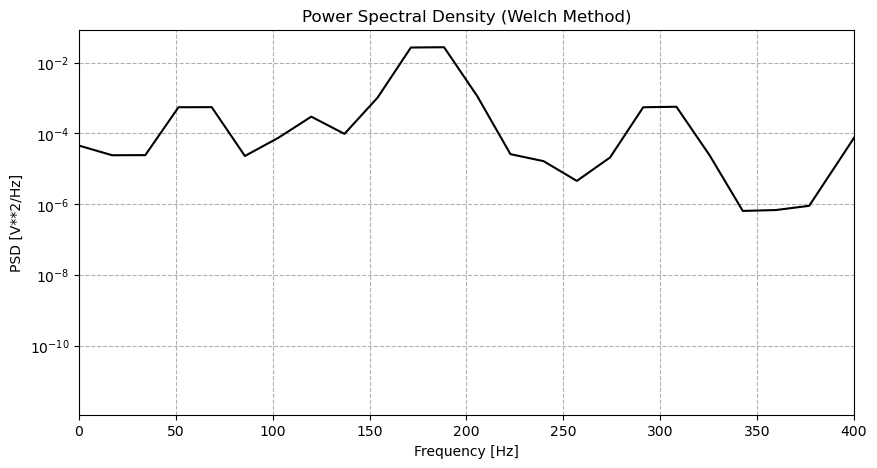

In [55]:
# 'nperseg' sets the length of each segment; larger values mean better frequency resolution
frequencies, psd = signal.welch(sig, fs=fs, nperseg=2*1024)

# 3. Plot the results
plt.figure(figsize=(10, 5))
plt.semilogy(frequencies, psd, color='black', lw=1.5)
plt.title('Power Spectral Density (Welch Method)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('PSD [V**2/Hz]')
plt.grid(True, which="both", ls="--")
plt.xlim(0, 400)  # Zoom into relevant frequency range
plt.show()

In [50]:
frequencies

array([    0.    ,    34.2646,    68.5293, ..., 17474.9707, 17509.2354,
       17543.5   ])

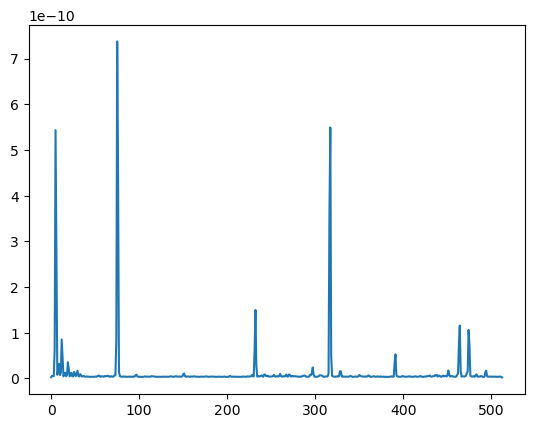

In [38]:
plt.plot(psd[1,:])